In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving googleplaystore.csv.zip to googleplaystore.csv.zip


In [ ]:
df = pd.read_csv("googleplaystore.csv.zip", low_memory=False)

In [ ]:
df.shape

(10841, 13)

In [ ]:
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [ ]:
df.isnull().sum()

,0
App,0
Category,0
Rating,1474
Reviews,0
Size,0
Installs,0
Type,1
Price,0
Content Rating,1
Genres,0


In [ ]:
df.duplicated().sum()

np.int64(483)

In [ ]:
df = df.drop_duplicates()

df.shape

(10358, 13)

In [ ]:
df.isnull().sum()

,0
App,0
Category,0
Rating,1465
Reviews,0
Size,0
Installs,0
Type,1
Price,0
Content Rating,1
Genres,0


In [ ]:
df['Type'].value_counts(dropna=False)

,count
Type,
Free,9591
Paid,765
NaN,1
0,1


In [ ]:
df[df['Type'] == '0']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [ ]:
df[df['Type'].isnull()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
9148,Command & Conquer: Rivals,FAMILY,NaN,0,Varies with device,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device


In [ ]:
df = df.dropna(subset=['Type'])

df.shape

(10357, 13)

In [ ]:
df.isnull().sum()

,0
App,0
Category,0
Rating,1464
Reviews,0
Size,0
Installs,0
Type,0
Price,0
Content Rating,1
Genres,0


In [ ]:
df = df.dropna(subset=[
    'Content Rating',
    'Current Ver',
    'Android Ver'
])

df.shape

(10346, 13)

In [ ]:
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')

df['Reviews'].dtype

dtype('int64')

In [ ]:
df['Installs'] = df['Installs'].str.replace(',', '', regex=False)
df['Installs'] = df['Installs'].str.replace('+', '', regex=False)

df['Installs'] = pd.to_numeric(df['Installs'], errors='coerce')

df['Installs'].dtype

dtype('int64')

In [ ]:
df['Price'] = df['Price'].str.replace('$', '', regex=False)

df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df['Price'].dtype

dtype('float64')

In [ ]:
df['Size'] = df['Size'].str.replace('M', '', regex=False)

df['Size'] = df['Size'].str.replace('k', '', regex=False)
df['Size'] = pd.to_numeric(df['Size'], errors='coerce')

df['Size'].dtype

dtype('float64')

In [ ]:
df['Last Updated'] = pd.to_datetime(
    df['Last Updated'],
    errors='coerce'
)

df['Last Updated'].dtype

dtype('<M8[ns]')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10346 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             10346 non-null  object        
 1   Category        10346 non-null  object        
 2   Rating          8886 non-null   float64       
 3   Reviews         10346 non-null  int64         
 4   Size            8821 non-null   float64       
 5   Installs        10346 non-null  int64         
 6   Type            10346 non-null  object        
 7   Price           10346 non-null  float64       
 8   Content Rating  10346 non-null  object        
 9   Genres          10346 non-null  object        
 10  Last Updated    10346 non-null  datetime64[ns]
 11  Current Ver     10346 non-null  object        
 12  Android Ver     10346 non-null  object        
dtypes: datetime64[ns](1), float64(3), int64(2), object(7)
memory usage: 1.1+ MB


In [ ]:
df.isnull().sum()

,0
App,0
Category,0
Rating,1460
Reviews,0
Size,1525
Installs,0
Type,0
Price,0
Content Rating,0
Genres,0


In [ ]:
df['Rating'].describe()

,Rating
count,8886.000000
mean,4.187959
std,0.522428
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,5.000000


In [ ]:
average_rating = df['Rating'].mean()

print("Average App Rating:", round(average_rating, 2))

Average App Rating: 4.19


**Finding: Average App Rating**

The average rating of apps in the cleaned dataset is 4.19 out of 5. This suggests that users generally give positive ratings to apps on the Google Play Store. However, ratings are available for only 8,886 apps in the current dataset, so missing ratings are excluded from this calculation.

**Business Insight:** The company should aim to maintain high app quality, understand user feedback, and improve features that affect user satisfaction.

In [ ]:
unique_categories = df['Category'].nunique()

print("Number of Unique App Categories:", unique_categories)

Number of Unique App Categories: 33


**Finding: Number of Unique App Categories**

The dataset contains 33 unique app categories. These categories represent different types of applications available on the Google Play Store.

**Business Insight:** The company can compare app categories to identify market opportunities, understand user interests, and select suitable categories for future app development.

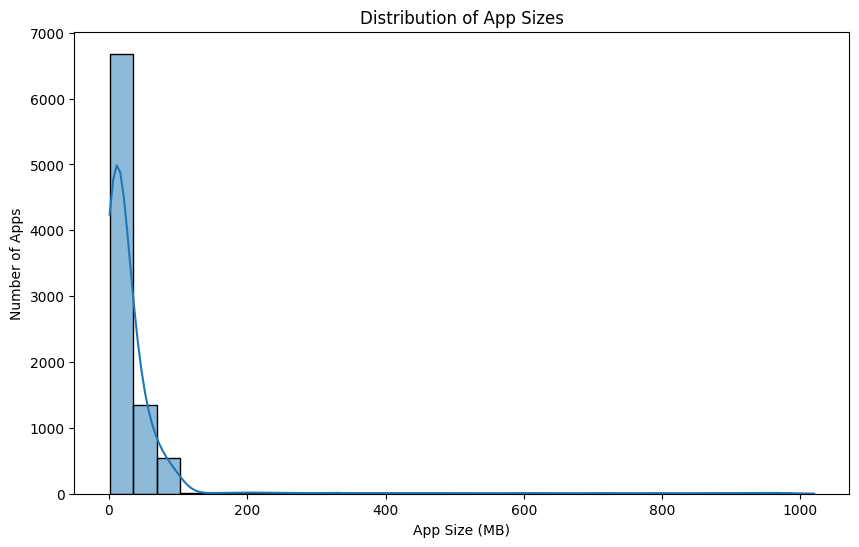

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='Size', bins=30, kde=True)

plt.title('Distribution of App Sizes')
plt.xlabel('App Size (MB)')
plt.ylabel('Number of Apps')

plt.show()

**Finding: Distribution of App Sizes**

The histogram shows how app sizes are distributed across the Google Play Store dataset. Apps with a fixed size are included in the chart, while apps with missing size values are excluded.

**Business Insight:** Developers should consider app size when designing mobile applications. Keeping apps optimized can help improve download convenience and the user experience, especially for users with limited device storage or slower internet connections.

In [ ]:
df['Type'].value_counts()

,count
Type,
Free,9584
Paid,762


### Finding: Free vs. Paid Apps

The analysis shows that the dataset contains 9,584 free apps and 762 paid apps. Free apps represent approximately 92.64% of all apps, while paid apps account for 7.36%.

**Business Insight:** The market is dominated by free apps. The company could consider a free-to-use model to attract more users and explore in-app purchases or premium features as potential revenue opportunities.

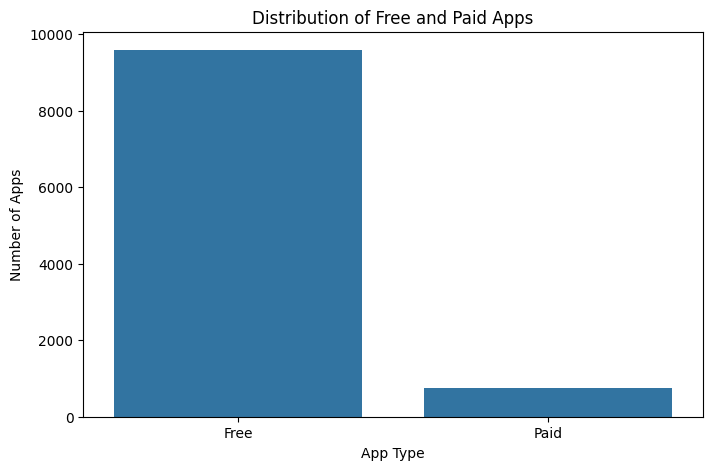

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Type')

plt.title('Distribution of Free and Paid Apps')
plt.xlabel('App Type')
plt.ylabel('Number of Apps')

plt.show()

In [ ]:
df['Content Rating'].value_counts()

,count
Content Rating,
Everyone,8372
Teen,1146
Mature 17+,447
Everyone 10+,376
Adults only 18+,3
Unrated,2


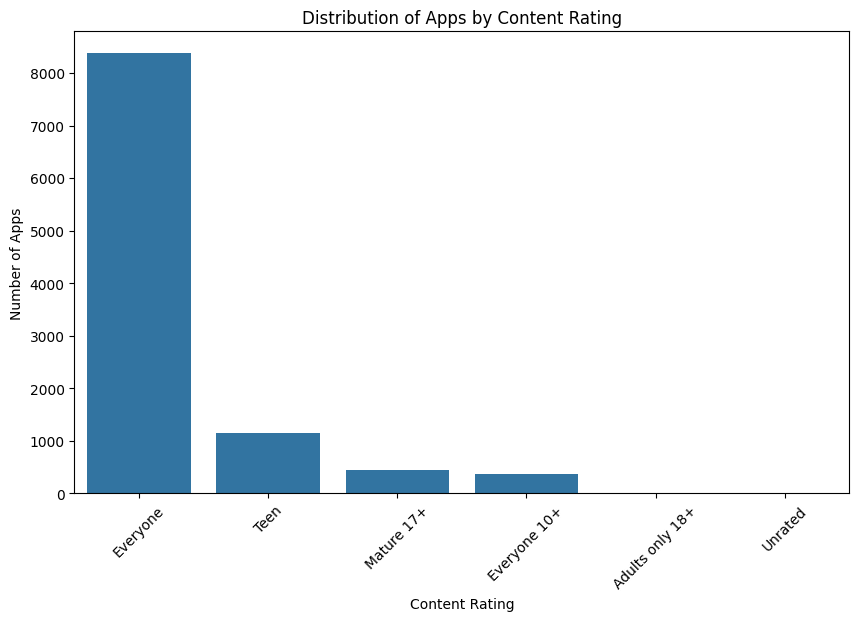

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Content Rating',
    order=df['Content Rating'].value_counts().index
)

plt.title('Distribution of Apps by Content Rating')
plt.xlabel('Content Rating')
plt.ylabel('Number of Apps')
plt.xticks(rotation=45)

plt.show()

In [ ]:
category_counts = df['Category'].value_counts()

print(category_counts.head(10))

Category
FAMILY             1939
GAME               1121
TOOLS               841
BUSINESS            427
MEDICAL             408
PRODUCTIVITY        407
PERSONALIZATION     386
LIFESTYLE           373
COMMUNICATION       366
FINANCE             360
Name: count, dtype: int64


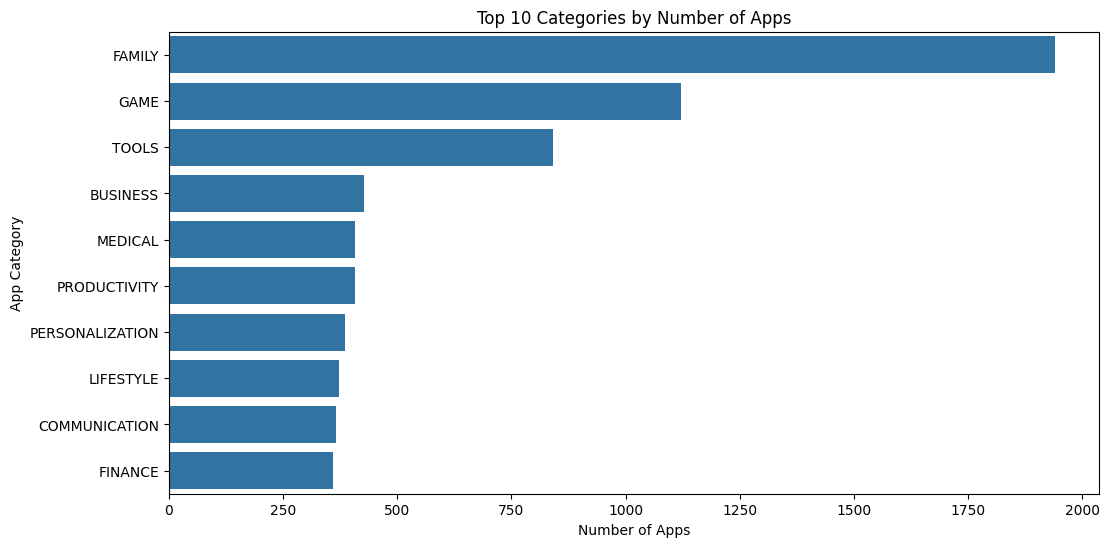

In [ ]:
plt.figure(figsize=(12, 6))

top_10_categories = df['Category'].value_counts().head(10)

sns.barplot(
    x=top_10_categories.values,
    y=top_10_categories.index
)

plt.title('Top 10 Categories by Number of Apps')
plt.xlabel('Number of Apps')
plt.ylabel('App Category')

plt.show()

In [ ]:
category_ratings = df.groupby('Category')['Rating'].mean().sort_values(ascending=False)

print(category_ratings.head(10).round(2))

Category
EVENTS                 4.44
ART_AND_DESIGN         4.38
EDUCATION              4.38
BOOKS_AND_REFERENCE    4.35
PERSONALIZATION        4.33
PARENTING              4.30
GAME                   4.28
BEAUTY                 4.28
HEALTH_AND_FITNESS     4.26
SOCIAL                 4.25
Name: Rating, dtype: float64


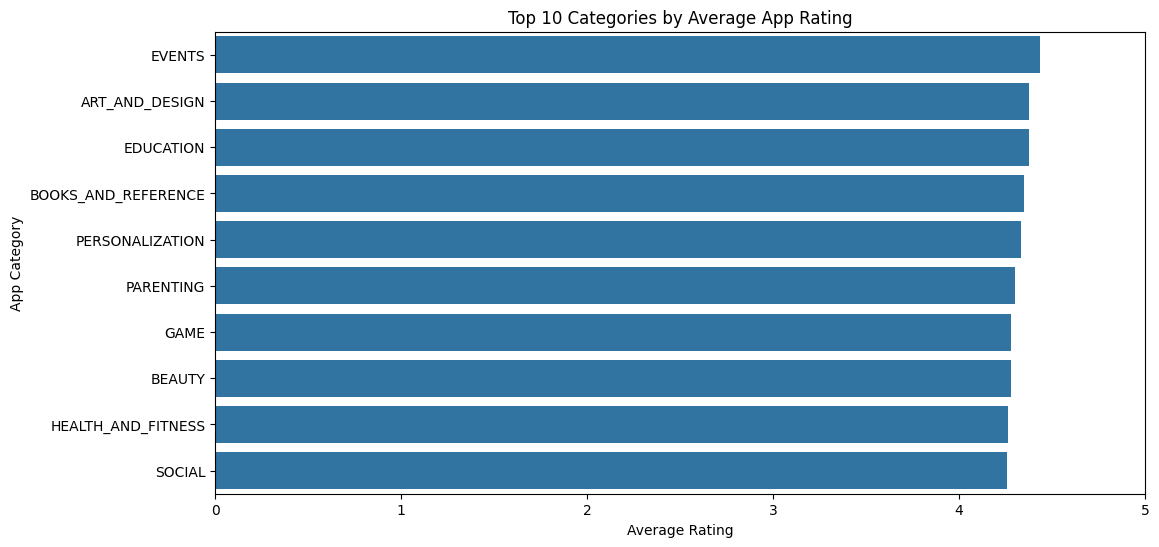

In [ ]:
plt.figure(figsize=(12, 6))

top_rated_categories = category_ratings.head(10)

sns.barplot(
    x=top_rated_categories.values,
    y=top_rated_categories.index
)

plt.title('Top 10 Categories by Average App Rating')
plt.xlabel('Average Rating')
plt.ylabel('App Category')
plt.xlim(0, 5)

plt.show()

In [ ]:
top_10_installed = df[['App', 'Installs', 'Category']].sort_values(
    by='Installs',
    ascending=False
).head(10)

print(top_10_installed.to_string(index=False))

                      App   Installs           Category
            Google Photos 1000000000        PHOTOGRAPHY
             Google Drive 1000000000       PRODUCTIVITY
Maps - Navigate & Explore 1000000000   TRAVEL_AND_LOCAL
                 Hangouts 1000000000      COMMUNICATION
                   Google 1000000000              TOOLS
              Google News 1000000000 NEWS_AND_MAGAZINES
       Google Street View 1000000000   TRAVEL_AND_LOCAL
            Google Photos 1000000000        PHOTOGRAPHY
       Google Street View 1000000000   TRAVEL_AND_LOCAL
Maps - Navigate & Explore 1000000000   TRAVEL_AND_LOCAL


In [ ]:
top_10_installed = (
    df.groupby('App', as_index=False)
      .agg({
          'Installs': 'max',
          'Category': 'first'
      })
      .sort_values(by='Installs', ascending=False)
      .head(10)
)

print(top_10_installed.to_string(index=False))

                                     App   Installs            Category
                                 YouTube 1000000000       VIDEO_PLAYERS
                      WhatsApp Messenger 1000000000       COMMUNICATION
           Skype - free IM & video calls 1000000000       COMMUNICATION
                                  Google 1000000000               TOOLS
                            Google Drive 1000000000        PRODUCTIVITY
Messenger – Text and Video Chat for Free 1000000000       COMMUNICATION
               Maps - Navigate & Explore 1000000000    TRAVEL_AND_LOCAL
                          Subway Surfers 1000000000                GAME
                                Facebook 1000000000              SOCIAL
                       Google Play Books 1000000000 BOOKS_AND_REFERENCE


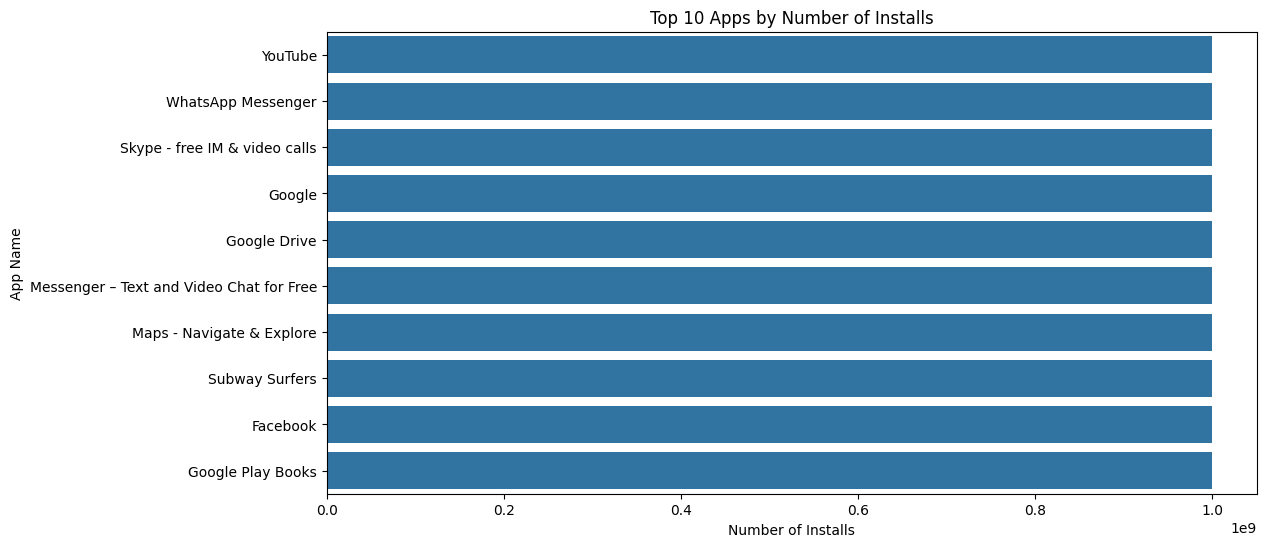

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_installed,
    x='Installs',
    y='App'
)

plt.title('Top 10 Apps by Number of Installs')
plt.xlabel('Number of Installs')
plt.ylabel('App Name')

plt.show()

**Finding: Top 10 Apps by Installs**

The analysis shows that all 10 apps in the top 10 list have 1 billion installs each. These apps belong to different categories, including Communication, Tools, Social, Games, and Productivity.

**Business Insight:** Popular apps can provide useful examples of successful app development and user engagement. The company can study their features and user experience to identify ideas for improving its own applications. However, install counts alone do not show user satisfaction or profitability.

In [ ]:
category_installs = (
    df.groupby('Category')['Installs']
      .sum()
      .sort_values(ascending=False)
)

print(category_installs.head(10))

Category
GAME                  31544024415
COMMUNICATION         24152276251
SOCIAL                12513867902
PRODUCTIVITY          12463091369
TOOLS                 11452271905
FAMILY                10041632405
PHOTOGRAPHY            9721247655
TRAVEL_AND_LOCAL       6361887146
VIDEO_PLAYERS          6222002720
NEWS_AND_MAGAZINES     5393217760
Name: Installs, dtype: int64


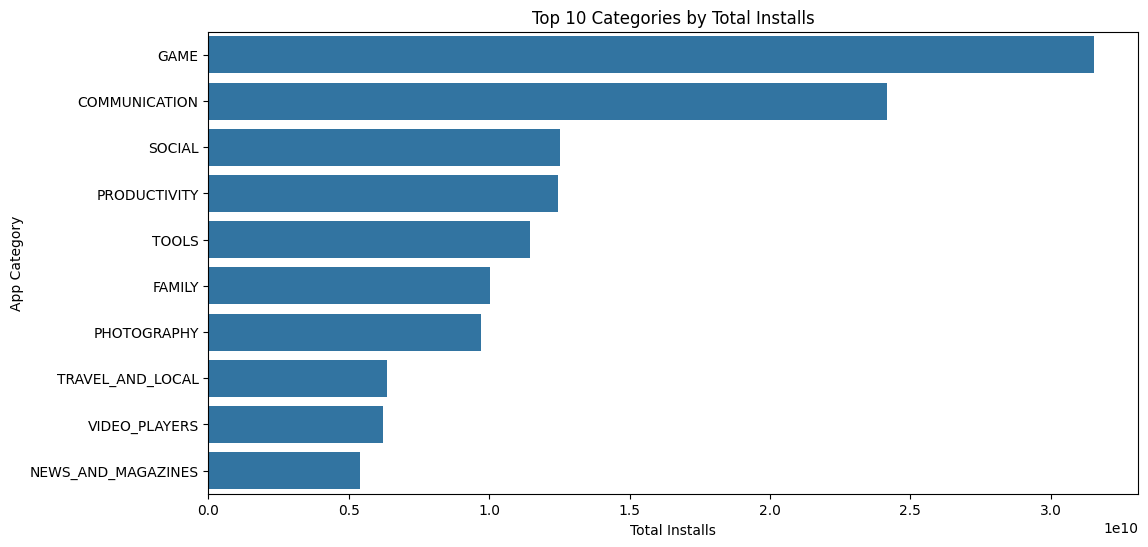

In [ ]:
plt.figure(figsize=(12, 6))

top_10_category_installs = category_installs.head(10)

sns.barplot(
    x=top_10_category_installs.values,
    y=top_10_category_installs.index
)

plt.title('Top 10 Categories by Total Installs')
plt.xlabel('Total Installs')
plt.ylabel('App Category')

plt.show()

**Finding: Categories by Total Installs**

The GAME category has the highest total number of installs, at approximately 31.54 billion. COMMUNICATION ranks second with 24.15 billion installs, followed by SOCIAL with 12.51 billion installs.

**Business Insight:** GAME and COMMUNICATION have strong install totals in this dataset. The company can study these categories to understand popular app features and user needs. However, total installs do not directly measure revenue or profitability.

In [ ]:
category_avg_installs = (
    df.groupby('Category')['Installs']
      .mean()
      .sort_values(ascending=False)
)

print(category_avg_installs.head(10).round(0).astype('int64'))

Category
COMMUNICATION         65989826
SOCIAL                44692385
VIDEO_PLAYERS         35554301
PRODUCTIVITY          30621846
PHOTOGRAPHY           30190210
GAME                  28139183
TRAVEL_AND_LOCAL      26843406
ENTERTAINMENT         22123063
NEWS_AND_MAGAZINES    20428855
TOOLS                 13617446
Name: Installs, dtype: int64


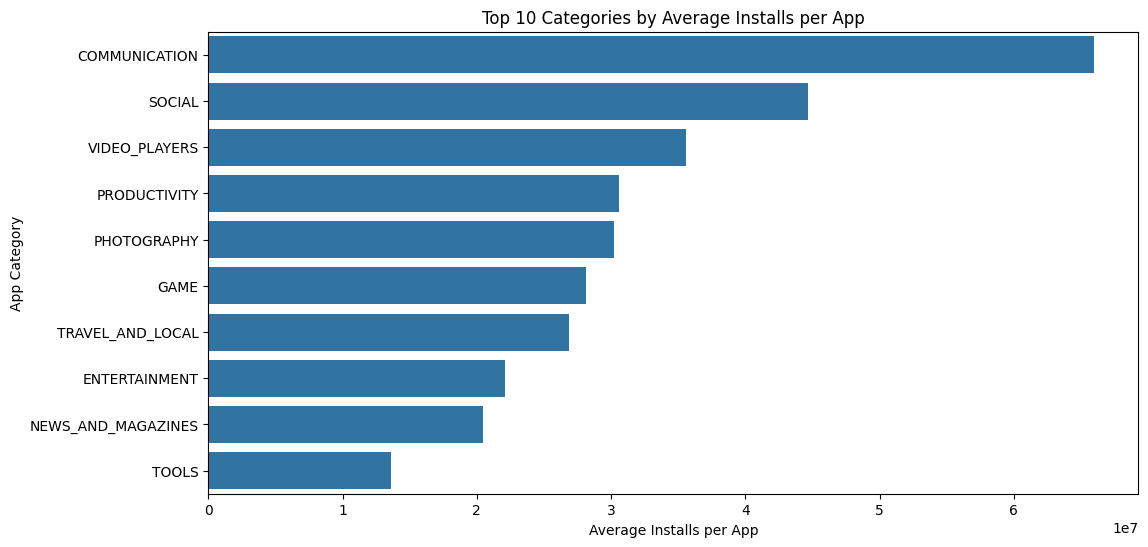

In [ ]:
plt.figure(figsize=(12, 6))

top_10_avg_installs = category_avg_installs.head(10)

sns.barplot(
    x=top_10_avg_installs.values,
    y=top_10_avg_installs.index
)

plt.title('Top 10 Categories by Average Installs per App')
plt.xlabel('Average Installs per App')
plt.ylabel('App Category')

plt.show()

**Finding: Categories by Average Installs per App**

The COMMUNICATION category has the highest average installs per app, at approximately 65.99 million. SOCIAL ranks second at 44.69 million, followed by VIDEO_PLAYERS at 35.55 million.

**Business Insight:** Communication and social apps show strong average install numbers in this dataset. The company can study these categories to understand user needs and popular features. However, high installs alone do not guarantee high revenue or user satisfaction.

In [ ]:
category_avg_price = (
    df.groupby('Category')['Price']
      .mean()
      .sort_values(ascending=False)
)

print(category_avg_price.head(10).round(2))

Category
FINANCE                8.06
LIFESTYLE              6.33
MEDICAL                2.50
EVENTS                 1.72
FAMILY                 1.25
PRODUCTIVITY           0.62
BOOKS_AND_REFERENCE    0.52
BUSINESS               0.41
WEATHER                0.40
PERSONALIZATION        0.39
Name: Price, dtype: float64


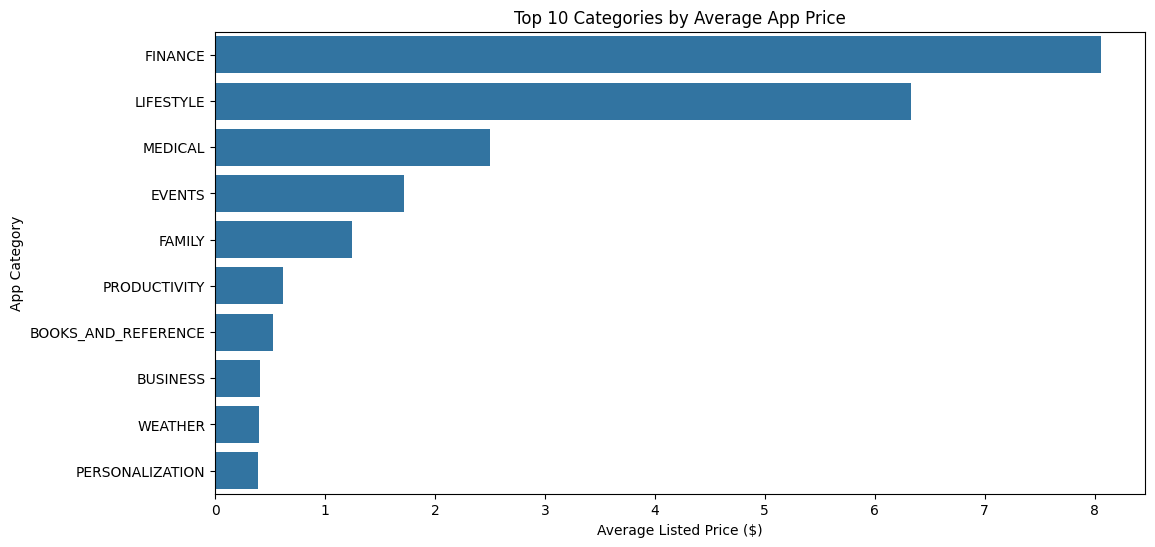

In [ ]:
plt.figure(figsize=(12, 6))

top_10_avg_price = category_avg_price.head(10)

sns.barplot(
    x=top_10_avg_price.values,
    y=top_10_avg_price.index
)

plt.title('Top 10 Categories by Average App Price')
plt.xlabel('Average Listed Price ($)')
plt.ylabel('App Category')

plt.show()

**Finding: Categories by Average App Price**

The FINANCE category has the highest average listed app price at $8.06, followed by LIFESTYLE at $6.33 and MEDICAL at $2.50. This shows that paid apps in these categories have higher average listed prices in the dataset.

**Business Insight:** The company can study pricing strategies in Finance, Lifestyle, and Medical apps when planning its own pricing model. However, average listed price does not represent actual revenue, since it does not account for purchases, downloads, or operating costs.

In [ ]:
paid_apps = df[df['Type'] == 'Paid']

paid_category_counts = (
    paid_apps.groupby('Category')['App']
    .count()
    .sort_values(ascending=False)
)

print(paid_category_counts.head(10))

Category
FAMILY                 186
MEDICAL                 84
GAME                    83
PERSONALIZATION         81
TOOLS                   77
BOOKS_AND_REFERENCE     28
PRODUCTIVITY            28
COMMUNICATION           27
SPORTS                  24
PHOTOGRAPHY             20
Name: App, dtype: int64


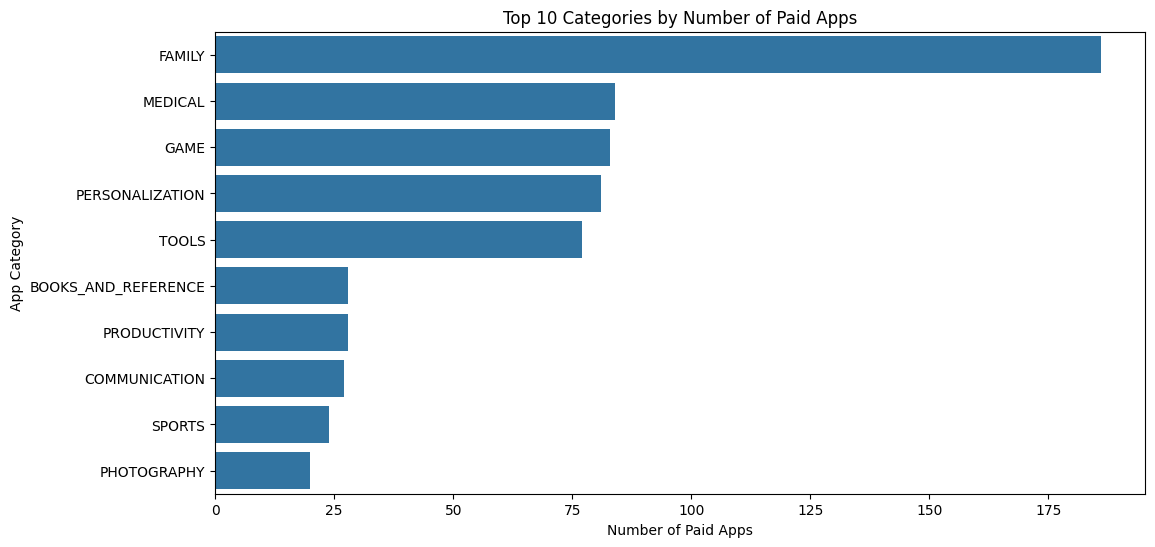

In [ ]:
plt.figure(figsize=(12, 6))

top_10_paid_categories = paid_category_counts.head(10)

sns.barplot(
    x=top_10_paid_categories.values,
    y=top_10_paid_categories.index
)

plt.title('Top 10 Categories by Number of Paid Apps')
plt.xlabel('Number of Paid Apps')
plt.ylabel('App Category')

plt.show()

**Finding: Categories with the Most Paid Apps**

The FAMILY category has the highest number of paid apps, with 186 apps. MEDICAL ranks second with 84 apps, followed by GAME with 83 apps.

**Business Insight:** The company can study paid apps in the FAMILY, MEDICAL, and GAME categories to understand how developers price their products. However, having more paid apps in a category does not necessarily mean that the category generates more revenue.

In [ ]:
paid_category_ratings = (
    df[df['Type'] == 'Paid']
    .groupby('Category')['Rating']
    .mean()
    .sort_values(ascending=False)
)

print(paid_category_ratings.head(10).round(2))

Category
NEWS_AND_MAGAZINES    4.80
EDUCATION             4.75
ART_AND_DESIGN        4.73
ENTERTAINMENT         4.60
AUTO_AND_VEHICLES     4.60
SHOPPING              4.50
PERSONALIZATION       4.45
HEALTH_AND_FITNESS    4.39
GAME                  4.37
WEATHER               4.37
Name: Rating, dtype: float64


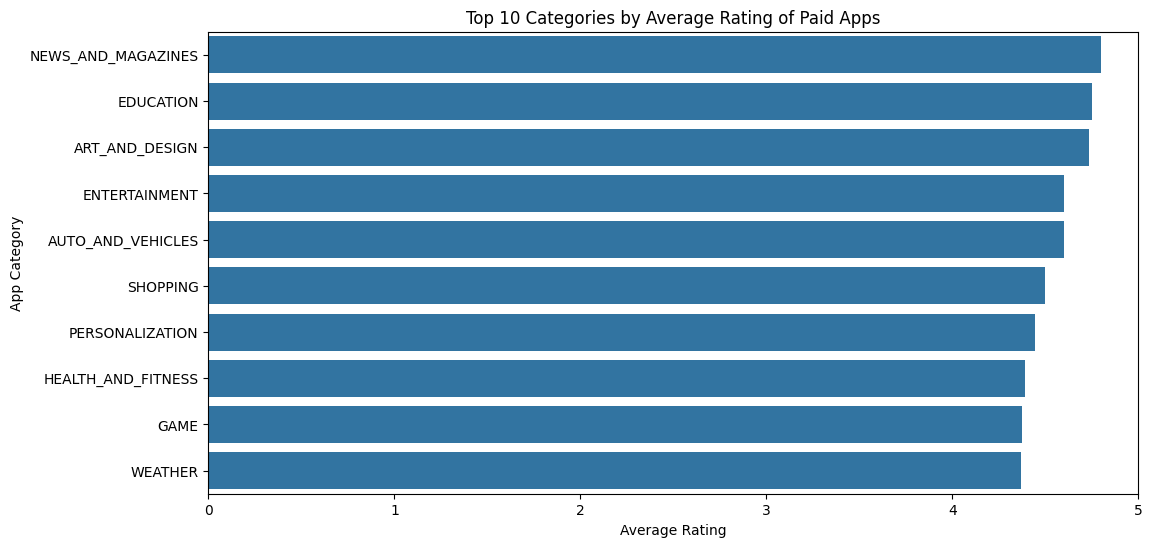

In [ ]:
plt.figure(figsize=(12, 6))

top_10_paid_ratings = paid_category_ratings.head(10)

sns.barplot(
    x=top_10_paid_ratings.values,
    y=top_10_paid_ratings.index
)

plt.title('Top 10 Categories by Average Rating of Paid Apps')
plt.xlabel('Average Rating')
plt.ylabel('App Category')
plt.xlim(0, 5)

plt.show()

**Finding: Highest-Rated Paid App Categories**

NEWS_AND_MAGAZINES has the highest average rating among paid apps, at 4.80 out of 5. EDUCATION follows at 4.75, and ART_AND_DESIGN ranks third at 4.73.

**Business Insight:** The company can study paid apps in these categories to understand which features and experiences users value. However, the number of ratings in each category should also be checked, because a high average rating based on very few reviews may not represent all users.

In [ ]:
category_reviews = (
    df.groupby('Category')['Reviews']
      .sum()
      .sort_values(ascending=False)
)

print(category_reviews.head(10))

Category
GAME               1415536650
COMMUNICATION       601273552
SOCIAL              533576829
FAMILY              396771746
TOOLS               273181033
PHOTOGRAPHY         204297410
VIDEO_PLAYERS       110380188
PRODUCTIVITY        102554498
SHOPPING             94931162
PERSONALIZATION      75192744
Name: Reviews, dtype: int64


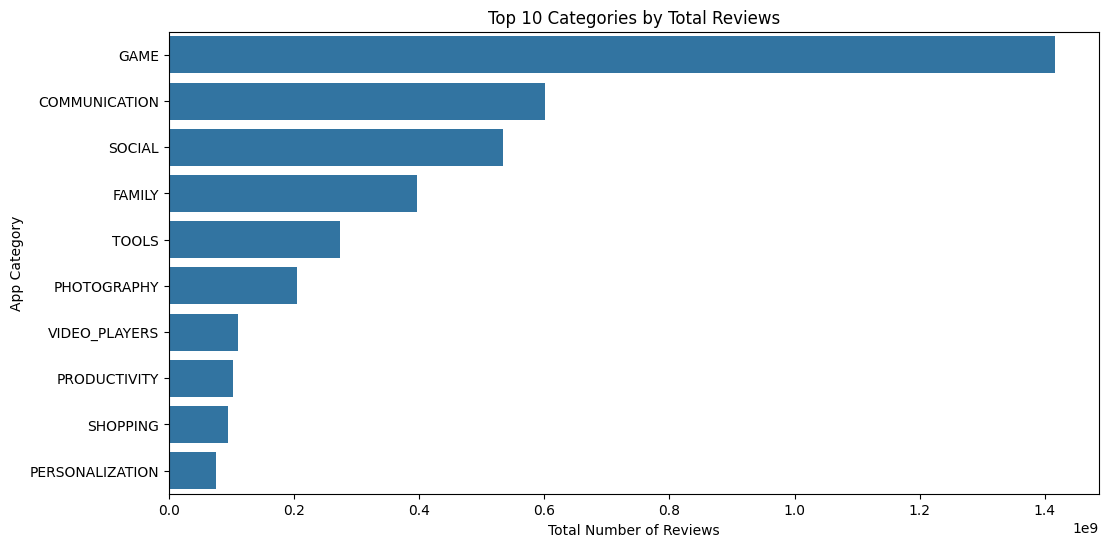

In [ ]:
plt.figure(figsize=(12, 6))

top_10_reviews = category_reviews.head(10)

sns.barplot(
    x=top_10_reviews.values,
    y=top_10_reviews.index
)

plt.title('Top 10 Categories by Total Reviews')
plt.xlabel('Total Number of Reviews')
plt.ylabel('App Category')

plt.show()

**Finding: Categories by Total Reviews**

The GAME category has the highest total number of reviews, at approximately 1.42 billion. COMMUNICATION ranks second with 601.27 million reviews, followed by SOCIAL with 533.58 million.

**Business Insight:** GAME, COMMUNICATION, and SOCIAL show high review volumes in this dataset. The company can study user feedback in these categories to understand common needs and identify opportunities to improve app features. However, total reviews alone do not indicate whether users are satisfied.

In [ ]:
df['Updated Year'] = df['Last Updated'].dt.year

yearly_updates = df['Updated Year'].value_counts().sort_index()

print(yearly_updates)

Updated Year
2010       1
2011      15
2012      26
2013     107
2014     204
2015     454
2016     787
2017    1823
2018    6929
Name: count, dtype: int64


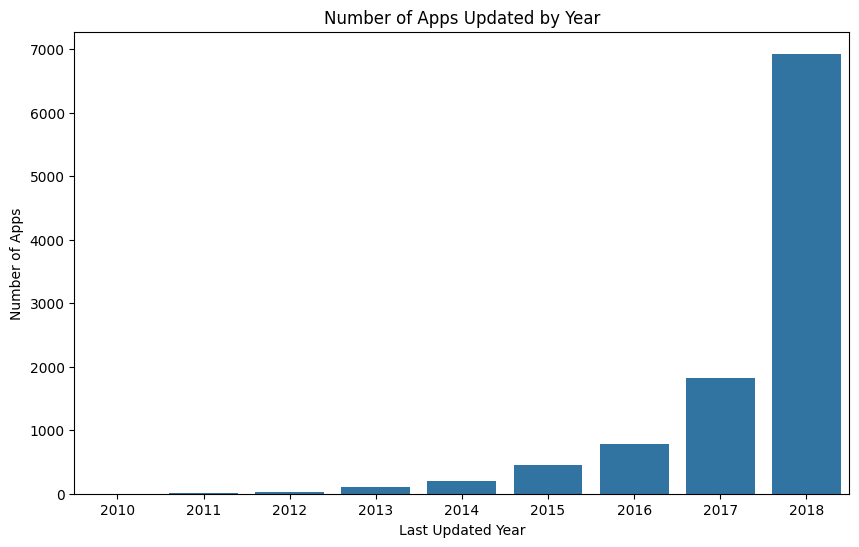

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=yearly_updates.index,
    y=yearly_updates.values
)

plt.title('Number of Apps Updated by Year')
plt.xlabel('Last Updated Year')
plt.ylabel('Number of Apps')

plt.show()

**Finding: App Updates by Year**

The analysis shows that 6,929 apps were last updated in 2018, making it the year with the highest number of updates in this dataset. The next highest year was 2017, with 1,823 apps.

**Business Insight:** Regular app updates can help developers improve features, fix bugs, and maintain compatibility. The company can study app update patterns to understand maintenance practices. However, this dataset only shows the last update date recorded for each app, not how frequently each app was updated.

# Conclusion – Google Play Store App Insights Analysis

In this project, I analyzed Google Play Store app data using Python, Pandas, NumPy, Matplotlib, and Seaborn. I cleaned the dataset, removed duplicate records, handled missing values, converted data types, and performed exploratory data analysis.

The analysis showed that the average app rating was 4.19 out of 5. The FAMILY category contained the highest number of apps, while GAME had the highest total installs and total reviews. COMMUNICATION had the highest average installs per app. The analysis also showed that free apps made up approximately 92.64% of the cleaned dataset, and FINANCE apps had the highest average listed price. Among paid apps, NEWS_AND_MAGAZINES had the highest average rating. Most apps in the dataset were last updated in 2018.

Overall, this project helped me understand app categories, ratings, installs, reviews, pricing, and update patterns. It also improved my practical skills in data cleaning, data analysis, visualization, and communicating business insights. These findings can help a company explore market trends and make more informed app development decisions.